# Superstore Sales Analysis — Exploratory Data Analysis (EDA)

## 1. Project Overview

This project analyses retail sales data to understand business performance, profitability, customer behaviour, product performance, regional trends and product returns.

The analysis uses Python to explore the Sample Superstore dataset and identify meaningful business insights.

## 2. Project Objectives

- Analyse overall sales and profit performance.
- Identify the most profitable product categories.
- Evaluate regional sales performance.
- Understand monthly and yearly sales trends.
- Identify top-performing products.
- Compare customer segments.
- Investigate the relationship between discounts and profitability.
- Calculate the overall order return rate.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## 4. Dataset

The project uses the Sample Superstore dataset, consisting of Orders, People and Returns data.

## 5. Expected Outcome

The objective is to transform raw retail data into meaningful insights and business recommendations that can support better decision-making.

Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading Orders dataset

In [6]:
import pandas as pd

df = pd.read_csv('/orders.csv')

In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,03-01-2023,07-01-2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.2,5.55
1,2,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.8,-5.49
2,3,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.2,4.27
3,4,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,0.2,-64.77
4,5,US-2023-141817,05-01-2023,12-01-2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.2,4.88


Number of rows and columns

In [8]:
df.shape

(10194, 21)

All column names

In [9]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

Column data types and missing values

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

Convert date columns

In [12]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y'
)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Su

In [14]:
df[['Order Date', 'Ship Date']].head()

,Order Date,Ship Date
0,2023-01-03,2023-01-07
1,2023-01-04,2023-01-08
2,2023-01-04,2023-01-08
3,2023-01-04,2023-01-08
4,2023-01-05,2023-01-12


Check missing values

In [15]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country/Region,0
City,0


In [16]:
df.isnull().sum().sum()

np.int64(0)

Check duplicate records

In [17]:
df.duplicated().sum()

np.int64(0)

Calculate the key business metrics

In [18]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_products = df['Product ID'].nunique()
total_quantity = df['Quantity'].sum()

profit_margin = (total_profit / total_sales) * 100

print("TOTAL SALES:", round(total_sales, 2))
print("TOTAL PROFIT:", round(total_profit, 2))
print("TOTAL ORDERS:", total_orders)
print("TOTAL CUSTOMERS:", total_customers)
print("UNIQUE PRODUCTS:", total_products)
print("TOTAL QUANTITY SOLD:", total_quantity)
print("PROFIT MARGIN:", round(profit_margin, 2), "%")

TOTAL SALES: 2326534.52
TOTAL PROFIT: 292297.4
TOTAL ORDERS: 5111
TOTAL CUSTOMERS: 804
UNIQUE PRODUCTS: 1862
TOTAL QUANTITY SOLD: 38654
PROFIT MARGIN: 12.56 %


Calculate total and average profit

In [19]:
print("Total Sales:", df['Sales'].sum())
print("Average Sales:", df['Sales'].mean())
print("Highest Sale:", df['Sales'].max())
print("Lowest Sale:", df['Sales'].min())

Total Sales: 2326534.52
Average Sales: 228.22587011967823
Highest Sale: 22638.48
Lowest Sale: 0.44


In [20]:
print("Total Profit:", df['Profit'].sum())
print("Average Profit:", df['Profit'].mean())

Total Profit: 292297.4
Average Profit: 28.673474592897787


In [21]:
print("Total Profit:", round(df['Profit'].sum(), 2))
print("Average Profit:", round(df['Profit'].mean(), 2))
print("Highest Profit:", round(df['Profit'].max(), 2))
print("Lowest Profit:", round(df['Profit'].min(), 2))

Total Profit: 292297.4
Average Profit: 28.67
Highest Profit: 8399.98
Lowest Profit: -6599.98


Calculate sales and profit by category

In [22]:
category_sales = df.groupby('Category')['Sales'].sum()

print(category_sales)

Category
Furniture          754747.94
Office Supplies    731893.23
Technology         839893.35
Name: Sales, dtype: float64


In [23]:
category_analysis = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
)

print(category_analysis.round(2))

                 Total_Sales  Total_Profit  Average_Profit
Category                                                  
Furniture          754747.94      19729.94            8.96
Office Supplies    731893.23     126023.44           20.57
Technology         839893.35     146544.02           78.58


Calculate profit margin

In [24]:
category_analysis['Profit_Margin'] = (
    category_analysis['Total_Profit'] /
    category_analysis['Total_Sales']
) * 100

print(category_analysis.round(2))

                 Total_Sales  Total_Profit  Average_Profit  Profit_Margin
Category                                                                 
Furniture          754747.94      19729.94            8.96           2.61
Office Supplies    731893.23     126023.44           20.57          17.22
Technology         839893.35     146544.02           78.58          17.45


Visualise category performance

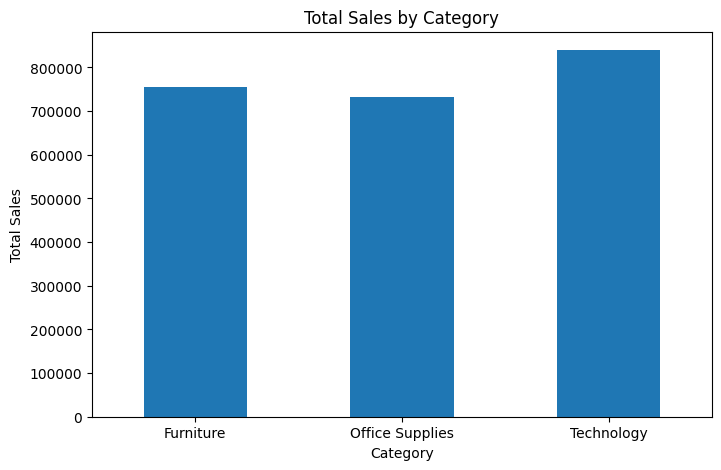

In [25]:
category_analysis['Total_Sales'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Category'
)

plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

Visualise profit by category

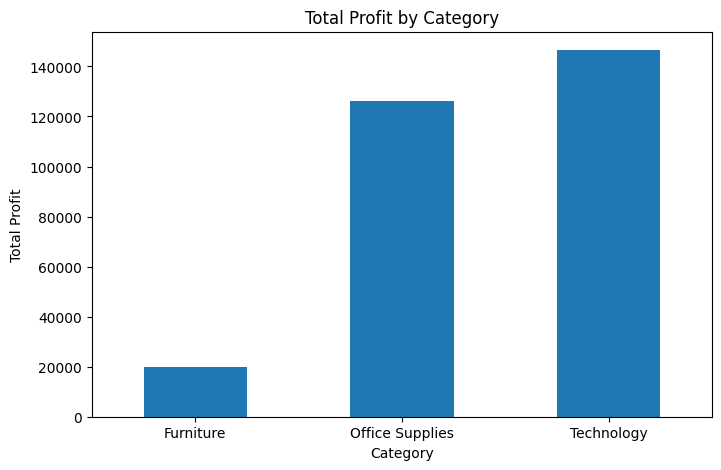

In [26]:
category_analysis['Total_Profit'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Profit by Category'
)

plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.show()

Created a profit margin chart

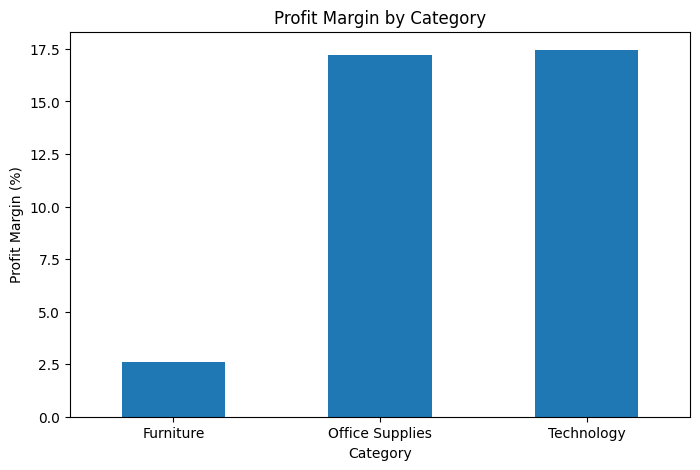

In [27]:
category_analysis['Profit_Margin'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Profit Margin by Category'
)

plt.xlabel('Category')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.show()

Regional Sales and Profit Analysis

In [28]:
region_analysis = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

print(region_analysis.round(2))

         Total_Sales  Total_Profit  Total_Quantity
Region                                            
Central    503170.66      39865.39            8820
East       691828.25      94883.27           11159
South      391721.90      46749.69            6209
West       739813.71     110799.05           12466


Calculate regional profit margins

In [29]:
region_analysis['Profit_Margin'] = (
    region_analysis['Total_Profit'] /
    region_analysis['Total_Sales']
) * 100

print(region_analysis.round(2))

         Total_Sales  Total_Profit  Total_Quantity  Profit_Margin
Region                                                           
Central    503170.66      39865.39            8820           7.92
East       691828.25      94883.27           11159          13.71
South      391721.90      46749.69            6209          11.93
West       739813.71     110799.05           12466          14.98


Visualise regional sales

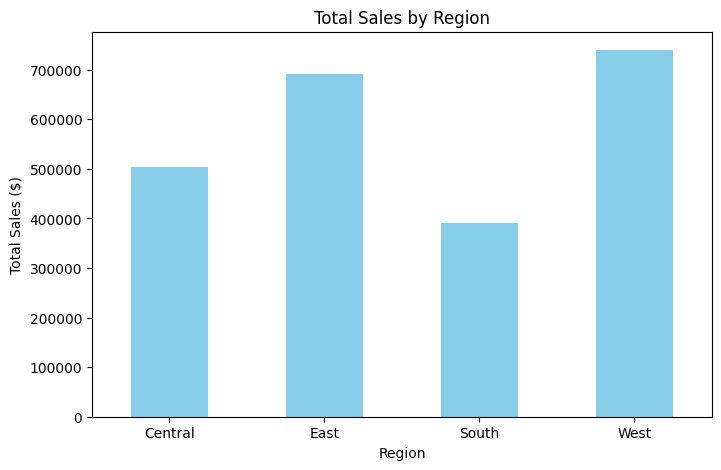

In [30]:
region_analysis['Total_Sales'].plot(
    kind='bar',
    figsize=(8, 5),
    color='skyblue',
    title='Total Sales by Region'
)

plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.show()

In [31]:
print(region_analysis.round(2))

         Total_Sales  Total_Profit  Total_Quantity  Profit_Margin
Region                                                           
Central    503170.66      39865.39            8820           7.92
East       691828.25      94883.27           11159          13.71
South      391721.90      46749.69            6209          11.93
West       739813.71     110799.05           12466          14.98


Monthly Sales Trend Analysis

In [32]:
df['Year_Month'] = df['Order Date'].dt.to_period('M')

monthly_sales = df.groupby('Year_Month').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

print(monthly_sales.head(15).round(2))

            Total_Sales  Total_Profit
Year_Month                           
2023-01        14518.06       2539.38
2023-02         4519.92        862.30
2023-03        56933.94        693.43
2023-04        28295.35       3488.86
2023-05        26319.76       3196.43
2023-06        34669.49       4999.80
2023-07        33946.37       -841.46
2023-08        28918.34       5765.21
2023-09        82670.42       8593.61
2023-10        32413.32       3469.14
2023-11        78826.98       9362.97
2023-12        72008.32       9554.65
2024-01        18461.92      -3189.77
2024-02        11951.40       2813.84
2024-03        39978.64       9930.58


Analyse monthly sales

In [33]:
df['Year_Month'] = df['Order Date'].dt.to_period('M')

monthly_sales = df.groupby('Year_Month').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

print(monthly_sales.round(2))

            Total_Sales  Total_Profit
Year_Month                           
2023-01        14518.06       2539.38
2023-02         4519.92        862.30
2023-03        56933.94        693.43
2023-04        28295.35       3488.86
2023-05        26319.76       3196.43
2023-06        34669.49       4999.80
2023-07        33946.37       -841.46
2023-08        28918.34       5765.21
2023-09        82670.42       8593.61
2023-10        32413.32       3469.14
2023-11        78826.98       9362.97
2023-12        72008.32       9554.65
2024-01        18461.92      -3189.77
2024-02        11951.40       2813.84
2024-03        39978.64       9930.58
2024-04        34195.25       4187.53
2024-05        30246.98       4677.09
2024-06        24797.31       3335.56
2024-07        28765.32       3288.71
2024-08        37056.99       5371.64
2024-09        64627.00       8220.02
2024-10        31407.11       2817.97
2024-11        75972.51      12474.79
2024-12        75532.55       8093.04
2025-01     

Visualise monthly sales

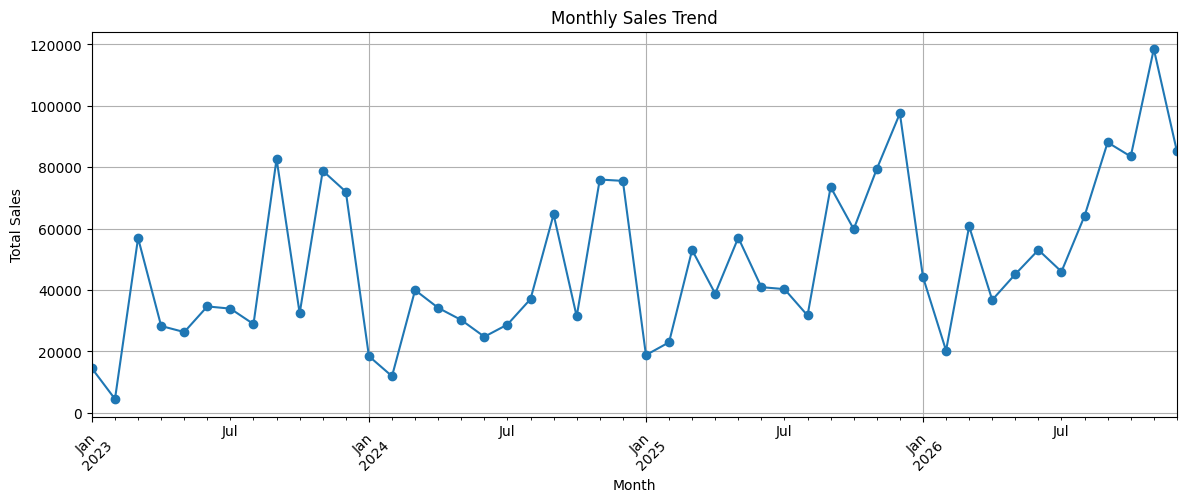

In [34]:
monthly_sales['Total_Sales'].plot(
    figsize=(14, 5),
    marker='o',
    title='Monthly Sales Trend'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Yearly Sales Analysis

In [35]:
yearly_sales = df.groupby(
    df['Order Date'].dt.year
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

yearly_sales['Profit_Margin'] = (
    yearly_sales['Total_Profit'] /
    yearly_sales['Total_Sales']
) * 100

print(yearly_sales.round(2))

            Total_Sales  Total_Profit  Profit_Margin
Order Date                                          
2023          494040.27      51684.32          10.46
2024          472992.98      62021.00          13.11
2025          613933.83      82665.27          13.46
2026          745567.44      95926.81          12.87


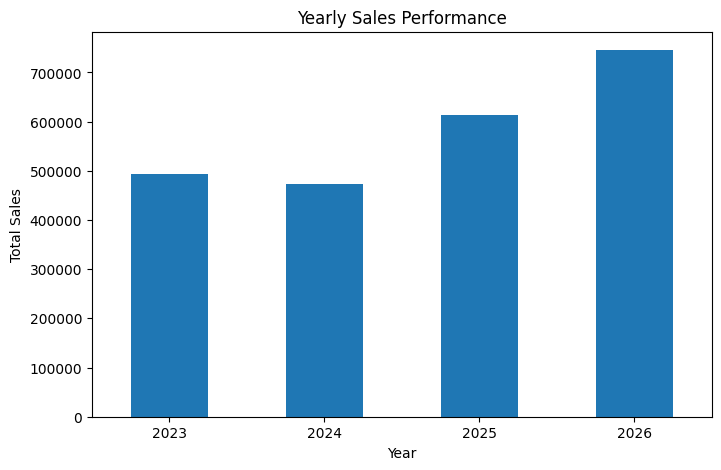

In [36]:
yearly_sales['Total_Sales'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Yearly Sales Performance'
)

plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

Top 10 Products Analysis

In [37]:
top_products = df.groupby('Product Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).sort_values(
    by='Total_Sales',
    ascending=False
).head(10)

print(top_products.round(2))

                                                    Total_Sales  Total_Profit  \
Product Name                                                                    
Canon imageCLASS 2200 Advanced Copier                  61599.83      25199.94   
Fellowes PB500 Electric Punch Plastic Comb Bind...     27453.38       7753.06   
Cisco TelePresence System EX90 Videoconferencin...     22638.48      -1811.08   
HON 5400 Series Task Chairs for Big and Tall           21870.57          0.00   
GBC DocuBind TL300 Electric Binding System             19823.48       2233.50   
GBC Ibimaster 500 Manual ProClick Binding System       19024.50        760.98   
Hewlett Packard LaserJet 3310 Copier                   18839.68       6983.89   
HP Designjet T520 Inkjet Large Format Printer -...     18374.90       4094.98   
GBC DocuBind P400 Electric Binding System              17965.07      -1878.17   
High Speed Automatic Electric Letter Opener            17030.31       -262.00   

                           

Customer Segment Analysis

In [38]:
segment_analysis = df.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Customers=('Customer ID', 'nunique')
)

segment_analysis['Profit_Margin'] = (
    segment_analysis['Total_Profit'] /
    segment_analysis['Total_Sales']
) * 100

print(segment_analysis.round(2))

             Total_Sales  Total_Profit  Total_Customers  Profit_Margin
Segment                                                               
Consumer      1170659.75     136371.48              416          11.65
Corporate      715806.20      94249.87              239          13.17
Home Office    440068.57      61676.05              149          14.02


Discount vs. Profitability Analysis

In [39]:
discount_analysis = df.groupby('Discount').agg(
    Total_Records=('Discount', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

discount_analysis['Profit_Margin'] = (
    discount_analysis['Total_Profit'] /
    discount_analysis['Total_Sales']
) * 100

print(discount_analysis.round(2))

          Total_Records  Total_Sales  Total_Profit  Profit_Margin
Discount                                                         
0.0                4925   1105323.79     326718.77          29.56
0.1                  96     54952.44       9100.00          16.56
0.2                3758    801497.87      92499.70          11.54
0.3                 257    118967.62     -12904.67         -10.85
0.4                 207    116497.80     -23086.40         -19.82
0.5                  77     64403.63     -22999.63         -35.71
0.6                 149      7105.92      -6164.34         -86.75
0.7                 424     40805.38     -40300.67         -98.76
0.8                 301     16980.07     -30565.36        -180.01


Visualise discount vs. profit margin

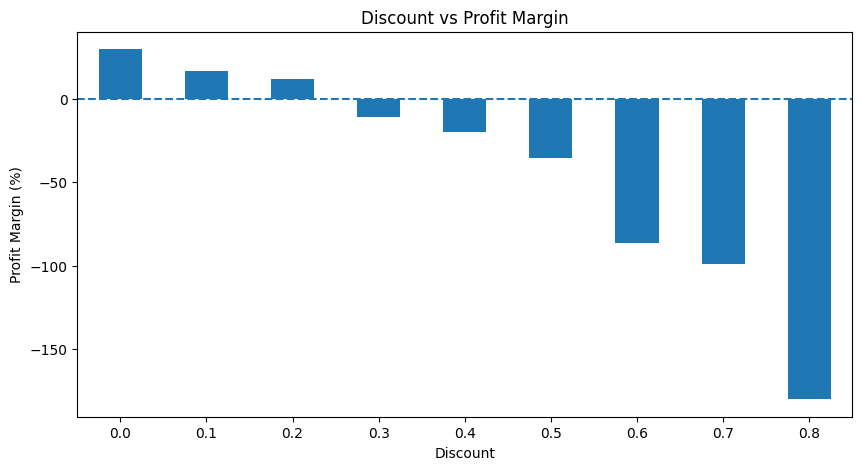

In [40]:
discount_analysis['Profit_Margin'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Discount vs Profit Margin'
)

plt.xlabel('Discount')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=0)
plt.axhline(y=0, linestyle='--')
plt.show()

Returns Analysis

In [42]:
returns_df = pd.read_csv('/returns.csv')

returns_df.head()

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


In [43]:

returns_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Order ID  296 non-null    object
 1   Returned  296 non-null    object
dtypes: object(2)
memory usage: 4.8+ KB


In [44]:
returns_df['Returned'].value_counts()

,count
Returned,
Yes,296


In [45]:
total_orders = df['Order ID'].nunique()

returned_orders = returns_df['Order ID'].nunique()

return_rate = (returned_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print("Return Rate:", round(return_rate, 2), "%")

Total Orders: 5111
Returned Orders: 296
Return Rate: 5.79 %


# 14. Final Business Insights and Recommendations

## Key Business Insights

### 1. Overall Performance
- Total sales: 2,326,534.52
- Total profit: 292,297.40
- Overall profit margin: 12.56%

### 2. Category Performance
- Technology generated the highest sales and profit.
- Office Supplies achieved a strong profit margin of 17.22%.
- Furniture had the lowest profit margin at 2.61%.

### 3. Regional Performance
- West was the strongest region, with the highest sales and profit.
- Central had the lowest profit margin at 7.92%.
- South generated the lowest sales.

### 4. Time-Based Performance
- Sales increased considerably from 2024 through 2026.
- 2026 recorded the highest sales and profit in the dataset.
- 2025 achieved the highest yearly profit margin at 13.46%.

*Note: 2026 may represent a partial year and should be compared cautiously with earlier years.*

### 5. Product Performance
- Canon imageCLASS 2200 Advanced Copier was the highest-revenue product.
- Some high-revenue products generated negative profits.

### 6. Customer Segment Performance
- Consumer generated the highest sales and total profit.
- Home Office achieved the highest profit margin at 14.02%.

### 7. Discount Analysis
- Transactions with discounts of 30% or higher recorded negative aggregate profits.
- Transactions without discounts achieved the highest profit margin of 29.56%.

### 8. Returns Analysis
- Total distinct orders: 5,111
- Returned orders: 296
- Overall order return rate: 5.79%

## Business Recommendations

1. Investigate the low profitability of Furniture products.
2. Review high-discount transactions and establish appropriate discount controls.
3. Investigate the Central region's relatively low profit margin.
4. Maintain the strong performance of Technology products.
5. Explore opportunities to grow Home Office sales while protecting profitability.
6. Investigate products generating high sales but negative profits.
7. Monitor return rates by product category and region to identify improvement opportunities.

## Conclusion

The Superstore Sales Analysis identified important patterns in sales, profitability, product performance, customer segments, regional performance, discounting and returns.

The findings demonstrate how Python and exploratory data analysis can transform raw retail data into actionable business insights.